In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from datasets import load_dataset, concatenate_datasets
import pandas as pd

# custom imports
from encoder import EncoderBooleanTransformer, tokenize_and_pad

In [2]:
def load_and_preprocess_data(dataset_name, num_words, max_length):
    dataset = load_dataset(dataset_name)
    tokenizer = Tokenizer(num_words=num_words, oov_token='<OOV>')
    tokenizer.fit_on_texts(dataset['train']['text'])

    X_train = tokenize_and_pad(dataset['train']['text'], tokenizer, max_length)
    y_train = np.array(dataset['train']['label'])
    
    X_test = tokenize_and_pad(dataset['test']['text'], tokenizer, max_length)
    y_test = np.array(dataset['test']['label'])

    if 'validation' in dataset:
        X_val = tokenize_and_pad(dataset['validation']['text'], tokenizer, max_length)
        y_val = np.array(dataset['validation']['label'])
        return X_train, y_train, X_test, y_test, X_val, y_val

    return X_train, y_train, X_test, y_test, None, None

In [17]:
def train_model(
    X_train, y_train, X_val, y_val, 
    num_layers, d_model, num_heads, dff, input_vocab_size, max_length, learning_rate, epochs,
    log_file='training_log.csv'
):
    model = EncoderBooleanTransformer(num_layers, d_model, num_heads, dff, input_vocab_size, max_length)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=['accuracy'])
    
    callback = tf.keras.callbacks.CSVLogger(log_file)

    if X_val is None or y_val is None:
        history = model.fit(X_train, y_train, batch_size=32, epochs=epochs, callbacks=[callback], validation_split=0.2)
    else:
        history = model.fit(X_train, y_train, batch_size=32, epochs=epochs, validation_data=(X_val, y_val), callbacks=[callback])
    
    return model, history

In [5]:
# hyperparameters
num_layers = 2
d_model = 256
num_heads = 8
dff = 512
num_words = 10000
input_vocab_size = num_words + 1
max_length = 120

In [6]:
# load and preprocess data
imdb_train_X, imdb_train_y, imdb_test_X, imdb_test_y, imdb_val_X, imdb_val_y = load_and_preprocess_data('imdb', num_words, max_length)
rt_train_X, rt_train_y, rt_test_X, rt_test_y, rt_val_X, rt_val_y = load_and_preprocess_data('rotten_tomatoes', num_words, max_length)

# other dataset?
# train_

In [8]:
# train model on 15 epochs, learning rate 0.0001
imdb_model, imdb_history = train_model(imdb_train_X, imdb_train_y, imdb_val_X, imdb_val_y, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, 0.0001, 15, 'imdb_training_log_0.0001.csv')

rt_model, rt_history = train_model(rt_train_X, rt_train_y, rt_val_X, rt_val_y, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, 0.0001, 15, 'rt_training_log_0.0001.csv')

Epoch 1/15
625/625 [==============================] - 42s 63ms/step - loss: 0.4596 - accuracy: 0.7670 - val_loss: 0.6542 - val_accuracy: 0.6924
Epoch 2/15
625/625 [==============================] - 39s 63ms/step - loss: 0.2600 - accuracy: 0.8934 - val_loss: 0.4880 - val_accuracy: 0.7948
Epoch 3/15
625/625 [==============================] - 39s 63ms/step - loss: 0.2015 - accuracy: 0.9237 - val_loss: 0.7667 - val_accuracy: 0.7468
Epoch 4/15
625/625 [==============================] - 39s 62ms/step - loss: 0.1565 - accuracy: 0.9411 - val_loss: 1.1366 - val_accuracy: 0.6738
Epoch 5/15
625/625 [==============================] - 38s 61ms/step - loss: 0.1196 - accuracy: 0.9572 - val_loss: 0.8038 - val_accuracy: 0.7228
Epoch 6/15
625/625 [==============================] - 39s 62ms/step - loss: 0.0977 - accuracy: 0.9667 - val_loss: 1.0675 - val_accuracy: 0.6968
Epoch 7/15
625/625 [==============================] - 39s 62ms/step - loss: 0.0774 - accuracy: 0.9737 - val_loss: 0.9243 - val_accuracy:

In [9]:
# evaluate model
imdb_loss, imdb_accuracy = imdb_model.evaluate(imdb_test_X, imdb_test_y)
rt_loss, rt_accuracy = rt_model.evaluate(rt_test_X, rt_test_y)

print(f'IMDB test loss: {imdb_loss}, accuracy: {imdb_accuracy}')
print(f'Rotten Tomatoes test loss: {rt_loss}, accuracy: {rt_accuracy}')

34/34 [==============================] - 1s 28ms/step - loss: 1.3399 - accuracy: 0.7617
IMDB test loss: 0.9585924744606018, accuracy: 0.7987599968910217
Rotten Tomatoes test loss: 1.3399301767349243, accuracy: 0.7617260813713074


c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: imdb_training_history.png
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: rt_training_history.png


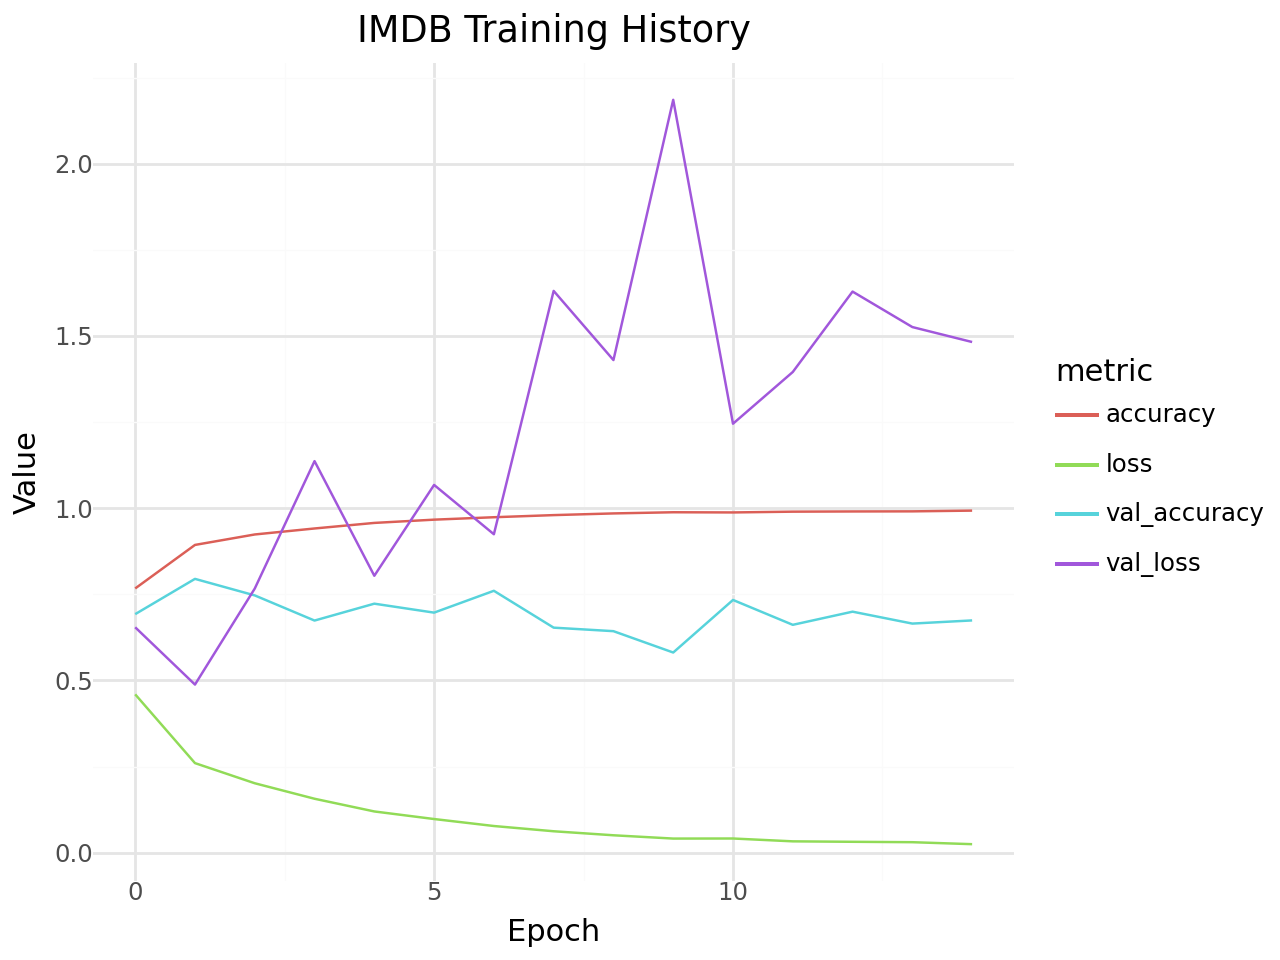

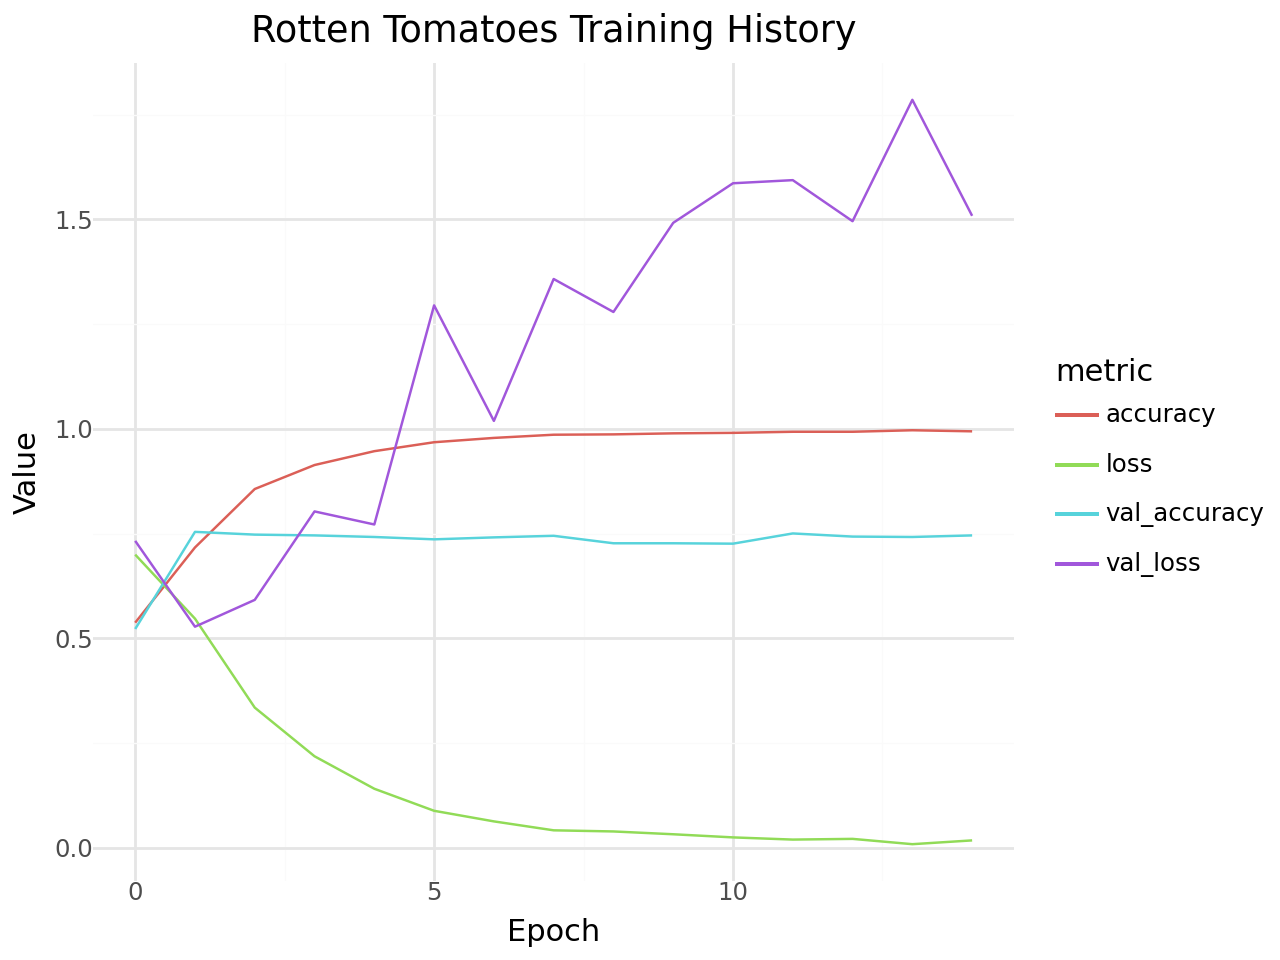

In [15]:
# plot training history curves
from plotnine import ggplot, aes, geom_line, scale_x_continuous, scale_y_continuous, theme_minimal, labs

imdb_history_df = pd.DataFrame(imdb_history.history)
imdb_history_df['epoch'] = imdb_history_df.index
imdb_history_df = imdb_history_df.melt(id_vars='epoch', var_name='metric', value_name='value')

rt_history_df = pd.DataFrame(rt_history.history)
rt_history_df['epoch'] = rt_history_df.index
rt_history_df = rt_history_df.melt(id_vars='epoch', var_name='metric', value_name='value')

# plot
imdb_plot = (
    ggplot(imdb_history_df, aes(x='epoch', y='value', color='metric')) +
    geom_line() +
    scale_x_continuous(name='Epoch') +
    scale_y_continuous(name='Value') +
    theme_minimal() +
    labs(title='IMDB Training History')
)
rt_plot = (
    ggplot(rt_history_df, aes(x='epoch', y='value', color='metric')) +
    geom_line() +
    scale_x_continuous(name='Epoch') +
    scale_y_continuous(name='Value') +
    theme_minimal() +
    labs(title='Rotten Tomatoes Training History')
)

imdb_plot.save('imdb_training_history_0.0001.png')
rt_plot.save('rt_training_history_0.0001.png')

imdb_plot.show()
rt_plot.show()


In [18]:
# train on learning rate 0.001
imdb_model2, imdb_history2 = train_model(imdb_train_X, imdb_train_y, imdb_val_X, imdb_val_y, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, 0.001, 15, 'training_log_imdb_0.001.csv')

rt_model2, rt_history2 = train_model(rt_train_X, rt_train_y, rt_val_X, rt_val_y, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, 0.001, 15, 'training_log_rt_0.001.csv')

Epoch 1/15
625/625 [==============================] - 40s 62ms/step - loss: 0.6307 - accuracy: 0.6553 - val_loss: 0.6776 - val_accuracy: 0.5100
Epoch 2/15
625/625 [==============================] - 39s 62ms/step - loss: 0.5440 - accuracy: 0.7297 - val_loss: 0.8159 - val_accuracy: 0.5324
Epoch 3/15
625/625 [==============================] - 38s 61ms/step - loss: 0.4926 - accuracy: 0.7603 - val_loss: 0.6631 - val_accuracy: 0.6526
Epoch 4/15
625/625 [==============================] - 38s 61ms/step - loss: 0.4627 - accuracy: 0.7824 - val_loss: 0.5877 - val_accuracy: 0.7414
Epoch 5/15
625/625 [==============================] - 38s 61ms/step - loss: 0.5047 - accuracy: 0.7576 - val_loss: 0.7615 - val_accuracy: 0.6456
Epoch 6/15
625/625 [==============================] - 38s 61ms/step - loss: 0.4936 - accuracy: 0.7616 - val_loss: 0.8843 - val_accuracy: 0.4918
Epoch 7/15
625/625 [==============================] - 38s 62ms/step - loss: 0.4822 - accuracy: 0.7671 - val_loss: 0.6070 - val_accuracy:

In [19]:
# evaluate model
imdb_loss2, imdb_accuracy2 = imdb_model2.evaluate(imdb_test_X, imdb_test_y)
rt_loss2, rt_accuracy2 = rt_model2.evaluate(rt_test_X, rt_test_y)

print(f'IMDB test loss: {imdb_loss2}, accuracy: {imdb_accuracy2}')
print(f'Rotten Tomatoes test loss: {rt_loss2}, accuracy: {rt_accuracy2}')

34/34 [==============================] - 1s 30ms/step - loss: 0.7122 - accuracy: 0.6848
IMDB test loss: 0.520695149898529, accuracy: 0.7557200193405151
Rotten Tomatoes test loss: 0.7121654748916626, accuracy: 0.6848030090332031


c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: imdb_training_history2.png
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: rt_training_history2.png


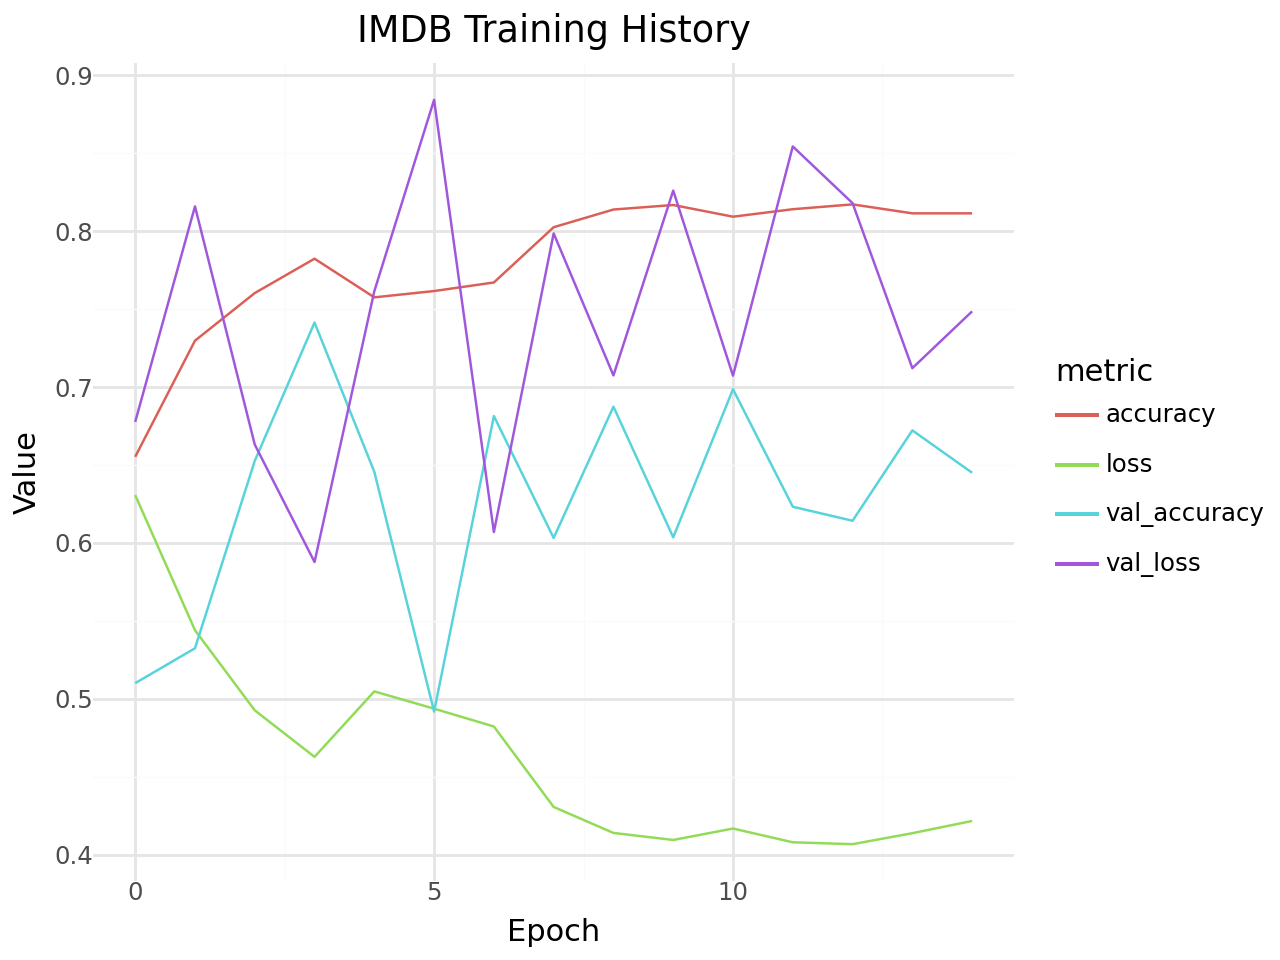

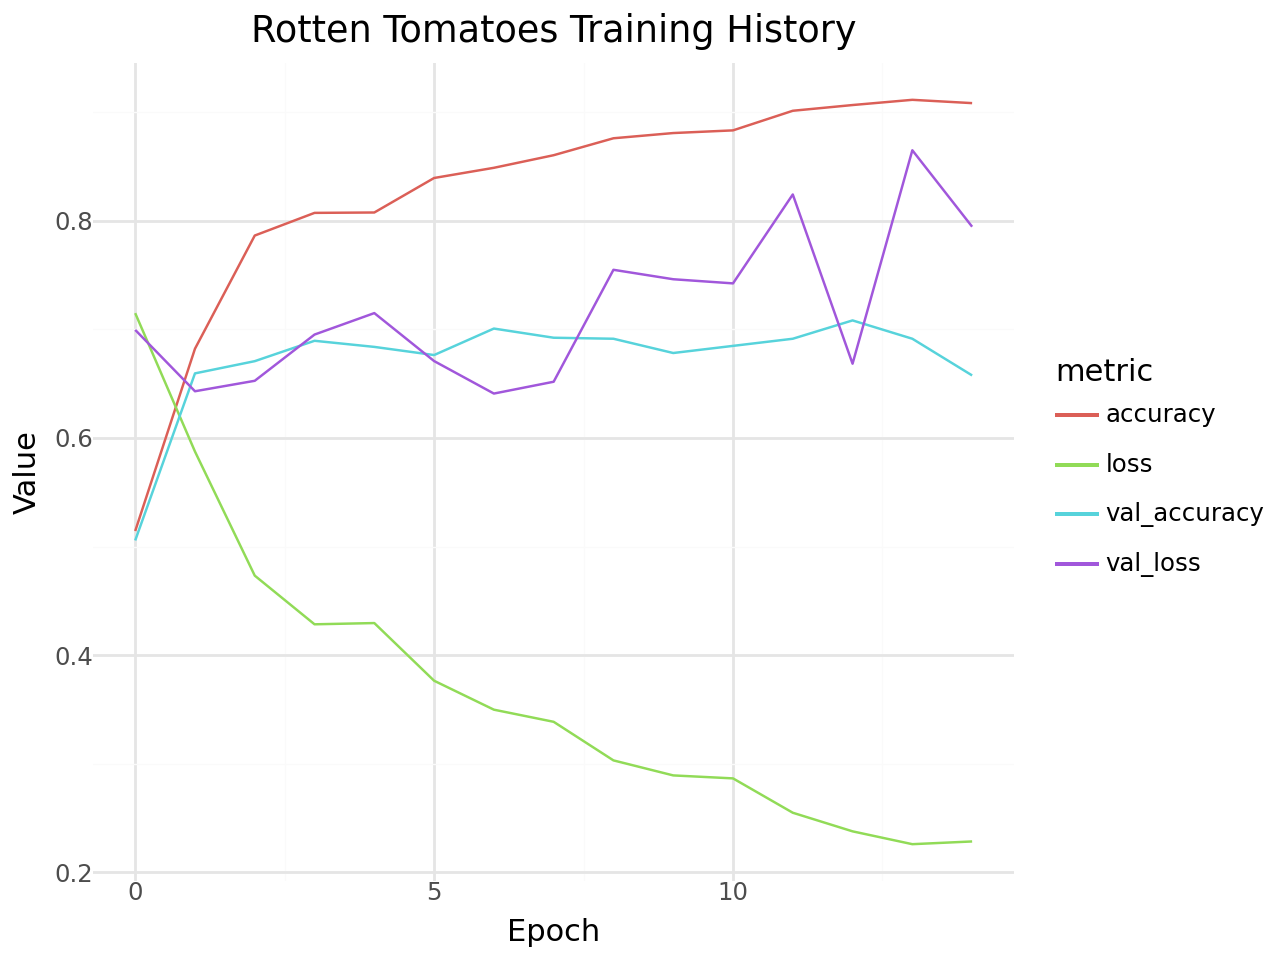

In [20]:
# plot training history curves
imdb_history_df2 = pd.DataFrame(imdb_history2.history)
imdb_history_df2['epoch'] = imdb_history_df2.index
imdb_history_df2 = imdb_history_df2.melt(id_vars='epoch', var_name='metric', value_name='value')

rt_history_df2 = pd.DataFrame(rt_history2.history)
rt_history_df2['epoch'] = rt_history_df2.index
rt_history_df2 = rt_history_df2.melt(id_vars='epoch', var_name='metric', value_name='value')

# plot
imdb_plot2 = (
    ggplot(imdb_history_df2, aes(x='epoch', y='value', color='metric')) +
    geom_line() +
    scale_x_continuous(name='Epoch') +
    scale_y_continuous(name='Value') +
    theme_minimal() +
    labs(title='IMDB Training History')
)

rt_plot2 = (
    ggplot(rt_history_df2, aes(x='epoch', y='value', color='metric')) +
    geom_line() +
    scale_x_continuous(name='Epoch') +
    scale_y_continuous(name='Value') +
    theme_minimal() +
    labs(title='Rotten Tomatoes Training History')
)

imdb_plot2.save('imdb_training_history_0.001.png')
rt_plot2.save('rt_training_history_0.001.png')

imdb_plot2.show()
rt_plot2.show()

In [21]:
# with learning rate = 0.00001
imdb_model3, imdb_history3 = train_model(imdb_train_X, imdb_train_y, imdb_val_X, imdb_val_y, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, 0.00001, 15, 'training_log_imdb_1e-5.csv')

rt_model3, rt_history3 = train_model(rt_train_X, rt_train_y, rt_val_X, rt_val_y, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, 0.00001, 15, 'training_log_rt_1e-5.csv')

Epoch 1/15
625/625 [==============================] - 41s 63ms/step - loss: 0.6481 - accuracy: 0.6286 - val_loss: 0.6558 - val_accuracy: 0.6270
Epoch 2/15
625/625 [==============================] - 38s 61ms/step - loss: 0.5495 - accuracy: 0.7229 - val_loss: 0.5453 - val_accuracy: 0.7266
Epoch 3/15
625/625 [==============================] - 38s 61ms/step - loss: 0.3910 - accuracy: 0.8243 - val_loss: 0.3948 - val_accuracy: 0.8294
Epoch 4/15
625/625 [==============================] - 38s 61ms/step - loss: 0.3320 - accuracy: 0.8535 - val_loss: 0.6252 - val_accuracy: 0.7170
Epoch 5/15
625/625 [==============================] - 38s 61ms/step - loss: 0.2998 - accuracy: 0.8708 - val_loss: 0.5918 - val_accuracy: 0.7408
Epoch 6/15
625/625 [==============================] - 38s 62ms/step - loss: 0.2715 - accuracy: 0.8863 - val_loss: 0.5958 - val_accuracy: 0.7458
Epoch 7/15
625/625 [==============================] - 38s 61ms/step - loss: 0.2521 - accuracy: 0.8965 - val_loss: 0.7474 - val_accuracy:

In [23]:
# evaluate model
imdb_loss3, imdb_accuracy3 = imdb_model3.evaluate(imdb_test_X, imdb_test_y)
rt_loss3, rt_accuracy3 = rt_model3.evaluate(rt_test_X, rt_test_y)

print(f'IMDB test loss: {imdb_loss3}, accuracy: {imdb_accuracy3}')
print(f'Rotten Tomatoes test loss: {rt_loss3}, accuracy: {rt_accuracy3}')

34/34 [==============================] - 1s 27ms/step - loss: 0.5750 - accuracy: 0.7711
IMDB test loss: 0.4315546751022339, accuracy: 0.8432400226593018
Rotten Tomatoes test loss: 0.5749995112419128, accuracy: 0.7711069583892822


c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: imdb_training_history3.png
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: rt_training_history3.png


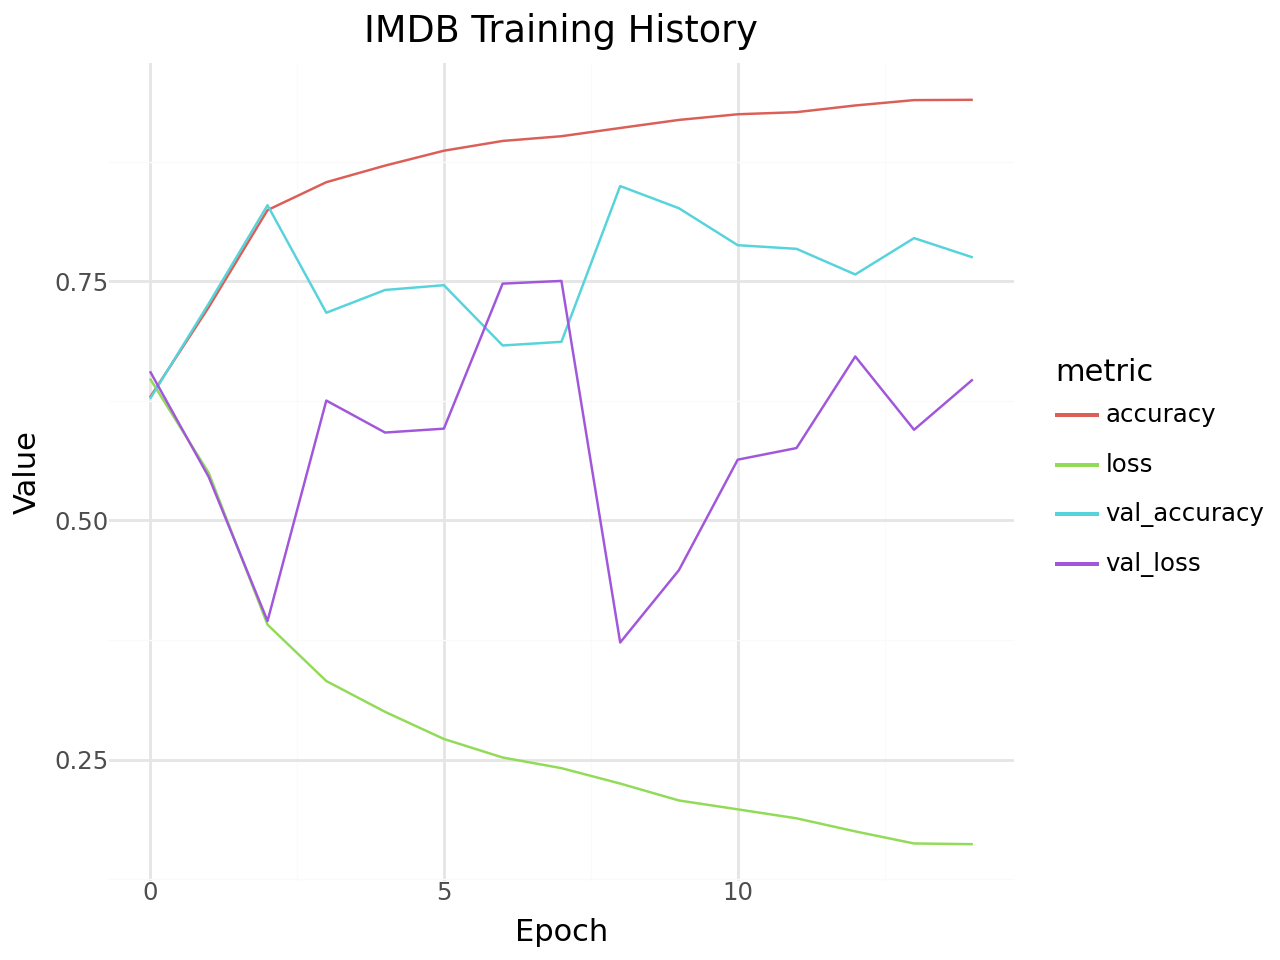

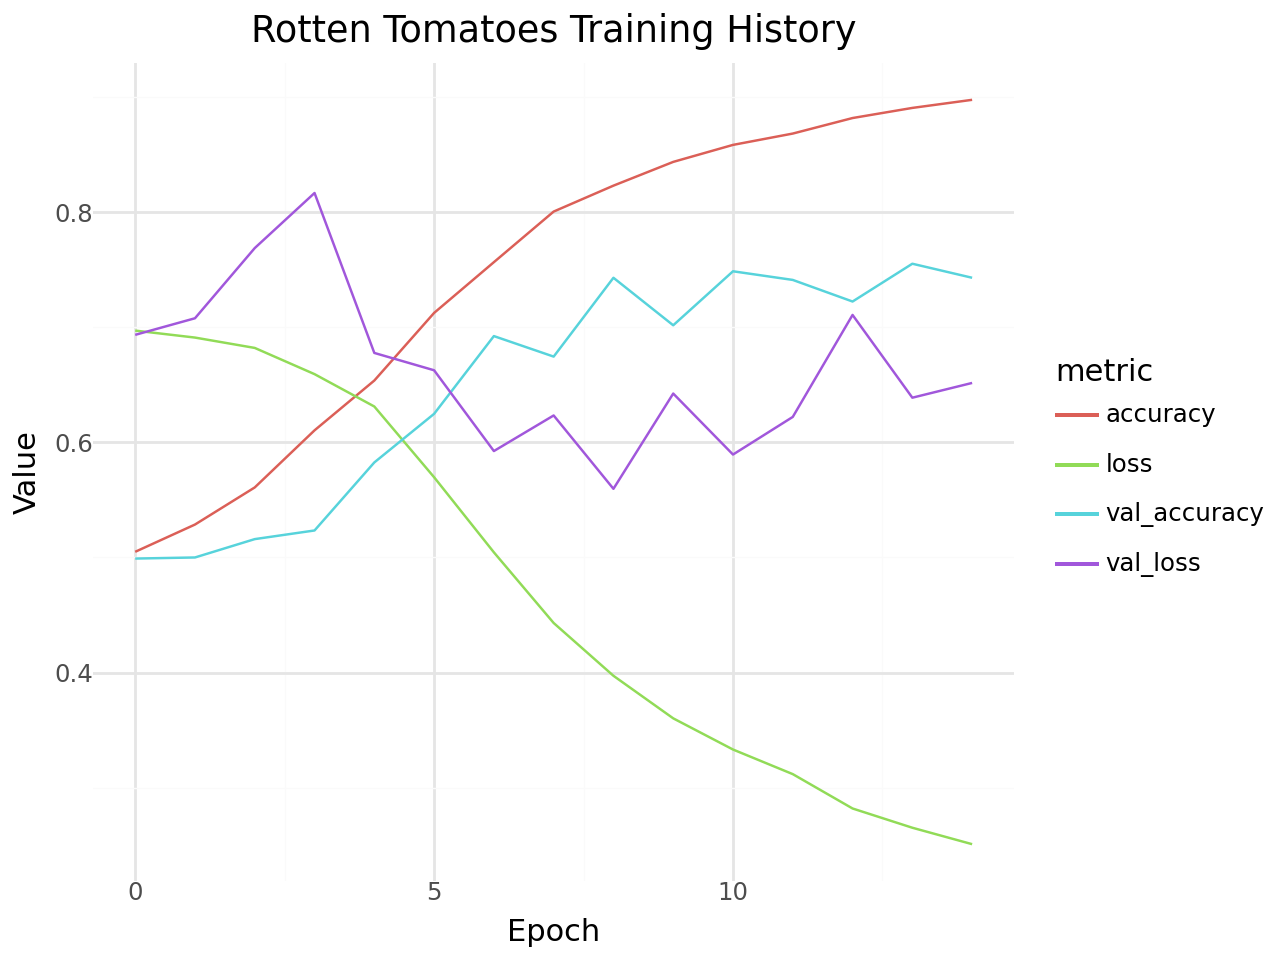

In [22]:
# plot training history curves
imdb_history_df3 = pd.DataFrame(imdb_history3.history)
imdb_history_df3['epoch'] = imdb_history_df3.index
imdb_history_df3 = imdb_history_df3.melt(id_vars='epoch', var_name='metric', value_name='value')

rt_history_df3 = pd.DataFrame(rt_history3.history)
rt_history_df3['epoch'] = rt_history_df3.index
rt_history_df3 = rt_history_df3.melt(id_vars='epoch', var_name='metric', value_name='value')

# plot
imdb_plot3 = (
    ggplot(imdb_history_df3, aes(x='epoch', y='value', color='metric')) +
    geom_line() +
    scale_x_continuous(name='Epoch') +
    scale_y_continuous(name='Value') +
    theme_minimal() +
    labs(title='IMDB Training History')
)

rt_plot3 = (
    ggplot(rt_history_df3, aes(x='epoch', y='value', color='metric')) +
    geom_line() +
    scale_x_continuous(name='Epoch') +
    scale_y_continuous(name='Value') +
    theme_minimal() +
    labs(title='Rotten Tomatoes Training History')
)

imdb_plot3.save('imdb_training_history3.png')
rt_plot3.save('rt_training_history3.png')

imdb_plot3.show()
rt_plot3.show()

In [24]:
import os
os.makedirs('results', exist_ok=True)

# for learning_rate in [1e-6, 1e-5, 1e-4, 1e-3]:
for learning_rate in [1e-6]:
    imdb_model, imdb_history = train_model(imdb_train_X, imdb_train_y, imdb_val_X, imdb_val_y, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, learning_rate, 15, f'results/imdb_training_log_{learning_rate}.csv')
    rt_model, rt_history = train_model(rt_train_X, rt_train_y, rt_val_X, rt_val_y, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, learning_rate, 15, f'results/rt_training_log_{learning_rate}.csv')

    imdb_loss, imdb_accuracy = imdb_model.evaluate(imdb_test_X, imdb_test_y)
    rt_loss, rt_accuracy = rt_model.evaluate(rt_test_X, rt_test_y)

    print(f'lr={learning_rate} IMDB test loss: {imdb_loss}, accuracy: {imdb_accuracy}')
    print(f'lr={learning_rate} Rotten Tomatoes test loss: {rt_loss}, accuracy: {rt_accuracy}')

    imdb_history_df = pd.DataFrame(imdb_history.history)
    imdb_history_df['epoch'] = imdb_history_df.index
    imdb_history_df = imdb_history_df.melt(id_vars='epoch', var_name='metric', value_name='value')

    rt_history_df = pd.DataFrame(rt_history.history)
    rt_history_df['epoch'] = rt_history_df.index
    rt_history_df = rt_history_df.melt(id_vars='epoch', var_name='metric', value_name='value')

    # plot
    imdb_plot = (
        ggplot(imdb_history_df, aes(x='epoch', y='value', color='metric')) +
        geom_line() +
        scale_x_continuous(name='Epoch') +
        scale_y_continuous(name='Value') +
        theme_minimal() +
        labs(title=f'IMDB Training History (lr={learning_rate})')
    )
    rt_plot = (
        ggplot(rt_history_df, aes(x='epoch', y='value', color='metric')) +
        geom_line() +
        scale_x_continuous(name='Epoch') +
        scale_y_continuous(name='Value') +
        theme_minimal() +
        labs(title=f'Rotten Tomatoes Training History (lr={learning_rate})')
    )

    imdb_plot.save(f'results/imdb_training_history_{learning_rate}.png')
    rt_plot.save(f'results/rt_training_history_{learning_rate}.png')

Epoch 1/15
625/625 [==============================] - 41s 63ms/step - loss: 0.6592 - accuracy: 0.6252 - val_loss: 1.0397 - val_accuracy: 0.0000e+00
Epoch 2/15
625/625 [==============================] - 39s 62ms/step - loss: 0.6547 - accuracy: 0.6251 - val_loss: 0.9850 - val_accuracy: 0.0000e+00
Epoch 3/15
625/625 [==============================] - 39s 62ms/step - loss: 0.6502 - accuracy: 0.6251 - val_loss: 1.0310 - val_accuracy: 0.0000e+00
Epoch 4/15
625/625 [==============================] - 39s 62ms/step - loss: 0.6454 - accuracy: 0.6255 - val_loss: 0.9468 - val_accuracy: 0.0016
Epoch 5/15
625/625 [==============================] - 39s 62ms/step - loss: 0.6401 - accuracy: 0.6259 - val_loss: 0.9748 - val_accuracy: 2.0000e-04
Epoch 6/15
625/625 [==============================] - 39s 62ms/step - loss: 0.6344 - accuracy: 0.6260 - val_loss: 0.9767 - val_accuracy: 0.0028
Epoch 7/15
625/625 [==============================] - 39s 62ms/step - loss: 0.6269 - accuracy: 0.6305 - val_loss: 0.9415

c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: results/imdb_training_history_1e-06.png
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\duynt\.conda\envs\csci373\lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: results/rt_training_history_1e-06.png


In [ ]:
# 1 epoch with lr=1e-3 , then 14 epochs with lr=1e-6 for imdb
def scheduler(epoch, lr):
    if epoch == 0:
        return 1e-3
    return 1e-6

from tensorflow.keras.callbacks import LearningRateScheduler

# Training function incorporating Learning Rate Scheduler
def train_model_schedule(X_train, y_train, X_val, y_val, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, epochs=15):
    model = EncoderBooleanTransformer(num_layers, d_model, num_heads, dff, input_vocab_size, max_length)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    # Define the Learning Rate Scheduler callback
    lr_scheduler = LearningRateScheduler(scheduler)

    # CSV Logger to log epoch results
    callback = tf.keras.callbacks.CSVLogger('training_log.csv')
    
    history = model.fit(X_train, y_train, batch_size=32, epochs=epochs, validation_data=(X_val, y_val), callbacks=[callback, lr_scheduler])
    
    return model, history

imdb_model, imdb_history = train_model_schedule(imdb_train_X, imdb_train_y, imdb_val_X, imdb_val_y, num_layers, d_model, num_heads, dff, input_vocab_size, max_length)

imdb_loss, imdb_accuracy = imdb_model.evaluate(imdb_test_X, imdb_test_y)

print(f'IMDB test loss: {imdb_loss}, accuracy: {imdb_accuracy}')

imdb_history_df = pd.DataFrame(imdb_history.history)

imdb_history_df['epoch'] = imdb_history_df.index

imdb_history_df = imdb_history_df.melt(id_vars='epoch', var_name='metric', value_name='value')

imdb_plot = (
    ggplot(imdb_history_df, aes(x='epoch', y='value', color='metric')) +
    geom_line() +
    scale_x_continuous(name='Epoch') +
    scale_y_continuous(name='Value') +
    theme_minimal() +
    labs(title='IMDB Training History')
)

imdb_plot.save('imdb_training_history_schedule.png')

imdb_plot.show()